In [1]:
%pip install ucimlrepo pandas openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Fetch the original dataset from UCI
credit_data = fetch_ucirepo(id=350)

# Extract features and target
X = credit_data.data.features
y = credit_data.data.targets

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget column:")
print(y.columns.tolist())

Features shape: (30000, 23)
Target shape: (30000, 1)

Feature columns:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']

Target column:
['Y']


In [3]:
# Inspect the dataset metadata
print("Feature metadata:")
print(credit_data.variables.to_string(index=False))

print("\nDataset description:")
print(credit_data.metadata.get("name"))

print("\nOriginal target information:")
print(credit_data.metadata.get("additional_info", {}))

Feature metadata:
name    role    type     demographic                description units missing_values
  ID      ID Integer            None                       None  None             no
  X1 Feature Integer            None                  LIMIT_BAL  None             no
  X2 Feature Integer             Sex                        SEX  None             no
  X3 Feature Integer Education Level                  EDUCATION  None             no
  X4 Feature Integer  Marital Status                   MARRIAGE  None             no
  X5 Feature Integer             Age                        AGE  None             no
  X6 Feature Integer            None                      PAY_0  None             no
  X7 Feature Integer            None                      PAY_2  None             no
  X8 Feature Integer            None                      PAY_3  None             no
  X9 Feature Integer            None                      PAY_4  None             no
 X10 Feature Integer            None           

In [4]:
# Combine features and target for inspection
df = pd.concat([X, y], axis=1)

print("=" * 50)
print("DATASET VERIFICATION")
print("=" * 50)

print("\nDataset dimensions:")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nColumn names:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(y.iloc[:, 0].value_counts().sort_index())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nFirst five rows:")
display(df.head())

# Check assignment requirements
assert len(df) >= 500, "Dataset does not meet the minimum row requirement."
assert X.shape[1] >= 12, "Dataset does not meet the minimum feature requirement."
assert y.shape[1] == 1, "Expected one target column."

print("\nAll minimum dataset-size requirements satisfied.")

DATASET VERIFICATION

Dataset dimensions:
Rows: 30000
Columns: 24

Column names:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'Y']

Target distribution:
Y
0    23364
1     6636
Name: count, dtype: int64

Missing values:
0

First five rows:


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0



All minimum dataset-size requirements satisfied.


In [5]:
# Combine the features and target
df = pd.concat([X, y], axis=1)

# Give the target a clear, consistent name
df = df.rename(
    columns={y.columns[0]: "default.payment.next.month"}
)

# Save the dataset
df.to_csv("credit_card_default.csv", index=False)

print("Dataset saved successfully.")
print("File: credit_card_default.csv")
print("Shape:", df.shape)

Dataset saved successfully.
File: credit_card_default.csv
Shape: (30000, 24)


In [6]:
# Step 2.1: Inspect the dataset before splitting

print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes.value_counts())

print("\nTarget distribution:")
print(df["default.payment.next.month"].value_counts())

print("\nTarget percentages:")
print(
    df["default.payment.next.month"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nMissing values per column:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (30000, 24)

Data types:
int64    24
Name: count, dtype: int64

Target distribution:
default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

Target percentages:
default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64

Missing values per column:
0

Duplicate rows: 35


In [7]:
# Inspect exact duplicate rows
duplicate_mask = df.duplicated(keep=False)

print("Rows involved in duplicates:", duplicate_mask.sum())

print("\nNumber of duplicate groups:")
print(df.loc[duplicate_mask].groupby(list(df.columns)).ngroups)

print("\nSample duplicate rows:")
display(df.loc[duplicate_mask].sort_values(
    by=list(df.columns)
).head(10))

Rows involved in duplicates: 70

Number of duplicate groups:
35

Sample duplicate rows:


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,default.payment.next.month
12430,20000,1,2,2,24,2,2,4,4,4,...,1650,1650,1650,0,0,0,0,0,0,1
14294,20000,1,2,2,24,2,2,4,4,4,...,1650,1650,1650,0,0,0,0,0,0,1
1759,50000,1,2,2,26,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
10250,50000,1,2,2,26,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
7170,50000,2,1,2,23,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
17032,50000,2,1,2,23,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
7366,80000,2,2,1,31,-2,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
19114,80000,2,2,1,31,-2,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
21768,80000,2,2,2,25,-2,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
27765,80000,2,2,2,25,-2,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0


In [8]:
from sklearn.model_selection import train_test_split

# Separate the features and target
target_column = "default.payment.next.month"

X = df.drop(columns=[target_column])
y = df[target_column]

# Create a reproducible, stratified 80:20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display split dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))

# Verify that the split has the expected dimensions
assert len(X_train) == 24000
assert len(X_test) == 6000
assert X_train.shape[1] == 23
assert X_test.shape[1] == 23

print("\nTrain-test split verified successfully.")

Training features: (24000, 23)
Testing features: (6000, 23)

Training target distribution:
default.payment.next.month
0    18691
1     5309
Name: count, dtype: int64
default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64

Testing target distribution:
default.payment.next.month
0    4673
1    1327
Name: count, dtype: int64
default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64

Train-test split verified successfully.


In [9]:
# Combine the held-out test features and target
test_data = X_test.copy()
test_data[target_column] = y_test

# Save the test dataset
test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully.")
print("File: test_data.csv")
print("Shape:", test_data.shape)

display(test_data.head())

Test dataset saved successfully.
File: test_data.csv
Shape: (6000, 24)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,default.payment.next.month
6907,50000,1,2,2,46,-1,-1,-1,-1,0,...,2650,3320,2764,26060,0,3472,2320,1764,2841,0
24575,150000,1,1,1,31,-1,-1,-2,-2,-2,...,0,0,11694,0,0,0,0,11694,30000,0
26766,50000,1,2,2,25,0,0,0,0,0,...,49949,50479,50702,1800,1844,2200,2000,1800,2038,0
2156,290000,2,1,2,25,0,0,0,0,0,...,248801,241983,230925,15000,10500,10000,15000,7844,23333,1
3179,500000,2,2,1,27,-2,-2,-2,-2,-2,...,10000,10000,10000,9983,13587,10000,10000,10000,25304,0


In [10]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

import joblib
from pathlib import Path

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [11]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Naive Bayes": GaussianNB()}

print("Models configured:")
for name in models:
    print("-", name)

Models configured:
- Logistic Regression
- Decision Tree
- KNN
- Naive Bayes


In [12]:
from pathlib import Path
import time
import joblib
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Directory for saving trained models
model_dir = Path("model")
model_dir.mkdir(parents=True, exist_ok=True)

# Store evaluation results
results = []
confusion_matrices = {}
classification_reports = {}
trained_models = {}

print("=" * 75)
print("TRAINING AND EVALUATING FIVE CLASSIFICATION MODELS")
print("=" * 75)

for name, model in models.items():

    print(f"\nTraining: {name}")
    start_time = time.time()

    # Train using training data only
    model.fit(X_train, y_train)

    # Predict class labels for the held-out test set
    y_pred = model.predict(X_test)

    # Obtain probabilities for the positive class (default = 1)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate all six required evaluation metrics
    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, y_pred)
    }

    results.append(metrics)

    # Save detailed evaluation information
    confusion_matrices[name] = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    classification_reports[name] = classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No Default (0)", "Default (1)"],
        zero_division=0
    )

    # Save each complete fitted model, including its scaler if applicable
    model_filename = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
        + ".joblib"
    )

    joblib.dump(model, model_dir / model_filename)
    trained_models[name] = model

    elapsed = time.time() - start_time
    print(f"Completed in {elapsed:.2f} seconds.")

# Create a comparison table
results_df = pd.DataFrame(results).set_index("Model")

# Display results rounded to four decimal places
print("\n" + "=" * 75)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 75)

display(results_df.round(4))

# Save the comparison table
results_df.to_csv("model_comparison.csv")

print("\nSaved evaluation table: model_comparison.csv")
print("Saved trained models in:", model_dir.resolve())

TRAINING AND EVALUATING FIVE CLASSIFICATION MODELS

Training: Logistic Regression
Completed in 0.36 seconds.

Training: Decision Tree
Completed in 3.46 seconds.

Training: KNN


c:\Users\sesha\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\sesha\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\sesha\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sesha\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

Completed in 8.73 seconds.

Training: Naive Bayes
Completed in 0.12 seconds.

MODEL PERFORMANCE COMPARISON


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8077,0.7076,0.6868,0.2396,0.3553,0.3244
Decision Tree,0.7145,0.6075,0.3694,0.4115,0.3893,0.2042
KNN,0.7928,0.7015,0.5487,0.3564,0.4322,0.3233
Naive Bayes,0.4160,0.6516,0.2496,0.8176,0.3824,0.1111



Saved evaluation table: model_comparison.csv
Saved trained models in: C:\Users\sesha\Documents\MTechAIMLBITS\1stSEM\4. ML\Assignment2\credit-card-default-ml-evaluation\model


In [14]:
import time
import joblib
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Configure a more efficient SVM
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        probability=False,
        cache_size=1000,
        random_state=42
    ))
])

print("Training SVM...")
start_time = time.time()

svm_model.fit(X_train, y_train)

print(f"Training completed in {time.time() - start_time:.2f} seconds.")

# Generate predictions and decision scores
svm_pred = svm_model.predict(X_test)
svm_scores = svm_model.decision_function(X_test)

# Calculate evaluation metrics
svm_results = {
    "Model": "Support Vector Machine",
    "Accuracy": accuracy_score(y_test, svm_pred),
    "AUC": roc_auc_score(y_test, svm_scores),
    "Precision": precision_score(y_test, svm_pred, zero_division=0),
    "Recall": recall_score(y_test, svm_pred, zero_division=0),
    "F1 Score": f1_score(y_test, svm_pred, zero_division=0),
    "MCC": matthews_corrcoef(y_test, svm_pred)
}

print("\nSVM evaluation:")
display(pd.DataFrame([svm_results]).set_index("Model").round(4))

# Save the trained model
Path("model").mkdir(exist_ok=True)
joblib.dump(svm_model, "model/support_vector_machine.joblib")

# Update the model dictionary
models["Support Vector Machine"] = svm_model
trained_models["Support Vector Machine"] = svm_model

print("SVM model saved successfully.")

Training SVM...
Training completed in 215.01 seconds.

SVM evaluation:


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Support Vector Machine,0.816,0.721,0.6652,0.3384,0.4486,0.3809


SVM model saved successfully.


In [15]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

import pandas as pd
import numpy as np

# Predict using the separately trained SVM
svm_pred = svm_model.predict(X_test)

# Get decision scores for AUC
svm_scores = svm_model.decision_function(X_test)

# Generate confusion matrix
svm_cm = confusion_matrix(y_test, svm_pred, labels=[0, 1])

print("SVM Confusion Matrix:")
print(svm_cm)

print("\nSVM Classification Report:")
print(classification_report(
    y_test,
    svm_pred,
    labels=[0, 1],
    target_names=["No Default (0)", "Default (1)"],
    zero_division=0
))

SVM Confusion Matrix:
[[4447  226]
 [ 878  449]]

SVM Classification Report:
                precision    recall  f1-score   support

No Default (0)       0.84      0.95      0.89      4673
   Default (1)       0.67      0.34      0.45      1327

      accuracy                           0.82      6000
     macro avg       0.75      0.64      0.67      6000
  weighted avg       0.80      0.82      0.79      6000



In [16]:
svm_results = {
    "Model": "Support Vector Machine",
    "Accuracy": accuracy_score(y_test, svm_pred),
    "AUC": roc_auc_score(y_test, svm_scores),
    "Precision": precision_score(
        y_test, svm_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, svm_pred, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, svm_pred, zero_division=0
    ),
    "MCC": matthews_corrcoef(y_test, svm_pred)
}

svm_results_df = pd.DataFrame([svm_results]).set_index("Model")

display(svm_results_df.round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Support Vector Machine,0.816,0.721,0.6652,0.3384,0.4486,0.3809


In [17]:
# Load the existing results table if it is already available
print("Existing results available:", "results_df" in globals())

if "results_df" in globals():
    print("\nExisting model results:")
    display(results_df.round(4))
else:
    print("The previous results table is not available in memory.")

Existing results available: True

Existing model results:


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8077,0.7076,0.6868,0.2396,0.3553,0.3244
Decision Tree,0.7145,0.6075,0.3694,0.4115,0.3893,0.2042
KNN,0.7928,0.7015,0.5487,0.3564,0.4322,0.3233
Naive Bayes,0.4160,0.6516,0.2496,0.8176,0.3824,0.1111


In [18]:
# Add SVM results to the existing comparison table
metric_columns = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

results_df.loc["Support Vector Machine", metric_columns] = [
    svm_results[metric] for metric in metric_columns
]

# Save the final comparison
results_df.to_csv("model_comparison.csv")

print("FINAL MODEL COMPARISON")
display(results_df.round(4))

print("\nSaved to model_comparison.csv")

FINAL MODEL COMPARISON


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8077,0.7076,0.6868,0.2396,0.3553,0.3244
Decision Tree,0.7145,0.6075,0.3694,0.4115,0.3893,0.2042
KNN,0.7928,0.7015,0.5487,0.3564,0.4322,0.3233
Naive Bayes,0.4160,0.6516,0.2496,0.8176,0.3824,0.1111
Support Vector Machine,0.8160,0.7210,0.6652,0.3384,0.4486,0.3809



Saved to model_comparison.csv


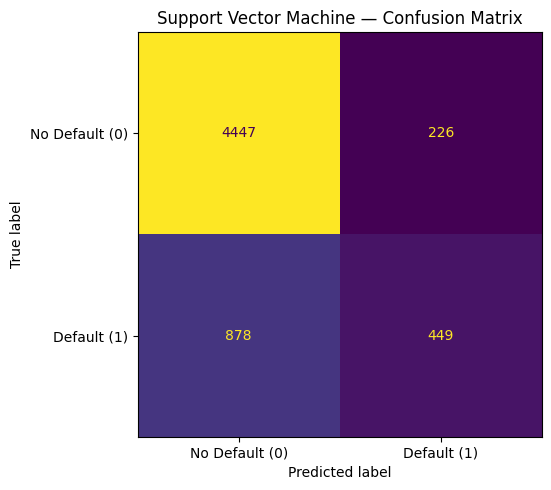

Saved: svm_confusion_matrix.png


In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=svm_cm,
    display_labels=["No Default (0)", "Default (1)"]
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title("Support Vector Machine — Confusion Matrix")
plt.tight_layout()
plt.savefig("svm_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved: svm_confusion_matrix.png")

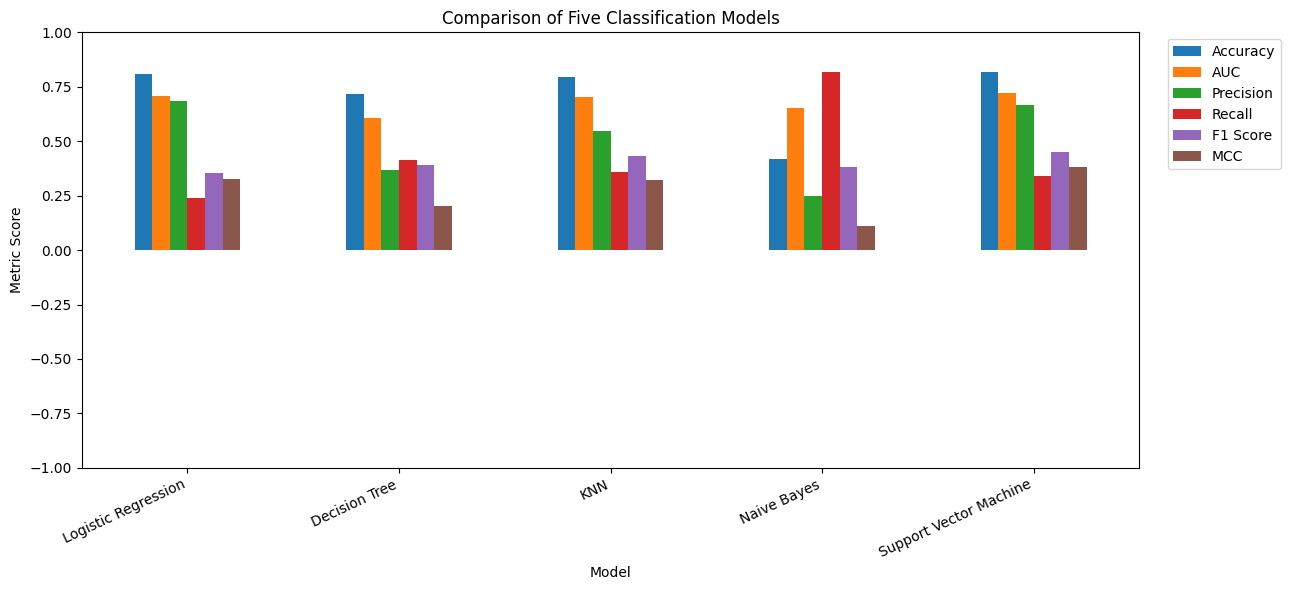

Saved: model_comparison.png


In [20]:
import matplotlib.pyplot as plt

metrics = [
    "Accuracy", "AUC", "Precision",
    "Recall", "F1 Score", "MCC"
]

ax = results_df[metrics].plot(
    kind="bar",
    figsize=(13, 6)
)

ax.set_title("Comparison of Five Classification Models")
ax.set_xlabel("Model")
ax.set_ylabel("Metric Score")
ax.set_ylim(-1, 1)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig("model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Saved: model_comparison.png")

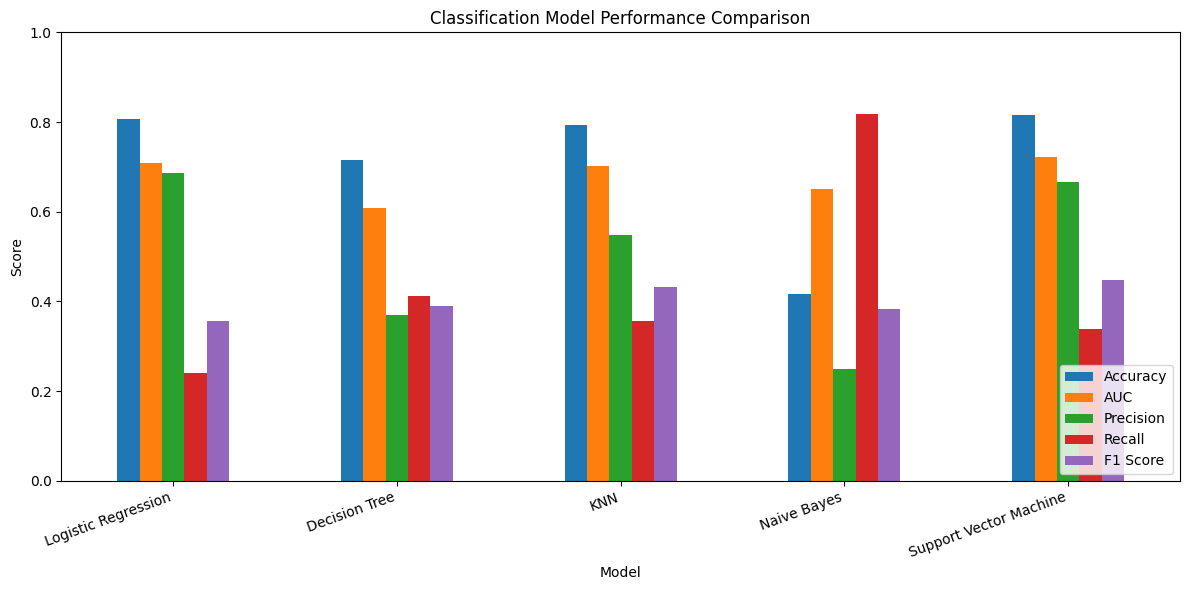

In [21]:
import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score"
]

ax = results_df[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Classification Model Performance Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)

plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    "model_comparison_readme.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

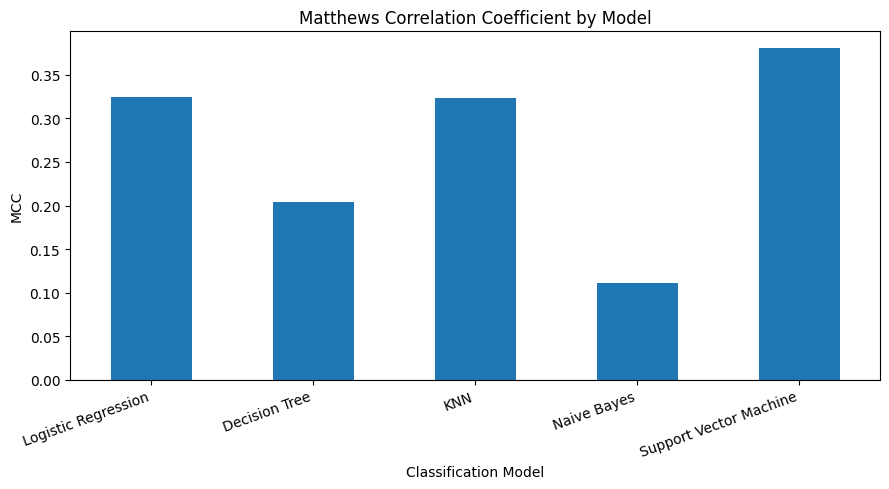

In [22]:
import matplotlib.pyplot as plt

# Compare MCC across all five classifiers
ax = results_df["MCC"].plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title("Matthews Correlation Coefficient by Model")
ax.set_xlabel("Classification Model")
ax.set_ylabel("MCC")
ax.axhline(y=0, linewidth=0.8)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig("mcc_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
display(results_df.round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8077,0.7076,0.6868,0.2396,0.3553,0.3244
Decision Tree,0.7145,0.6075,0.3694,0.4115,0.3893,0.2042
KNN,0.7928,0.7015,0.5487,0.3564,0.4322,0.3233
Naive Bayes,0.4160,0.6516,0.2496,0.8176,0.3824,0.1111
Support Vector Machine,0.8160,0.7210,0.6652,0.3384,0.4486,0.3809


In [24]:
from pathlib import Path

output_dir = Path("assignment_outputs")
output_dir.mkdir(exist_ok=True)

# Save the six-metric comparison table
results_df.to_csv(
    output_dir / "model_comparison.csv"
)

# Save all confusion matrices as a single CSV
confusion_matrix_rows = []

for model_name, cm in confusion_matrices.items():
    confusion_matrix_rows.append({
        "Model": model_name,
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1]
    })

confusion_matrix_df = pd.DataFrame(
    confusion_matrix_rows
)

confusion_matrix_df.to_csv(
    output_dir / "confusion_matrix_results.csv",
    index=False
)

print("Evaluation artifacts saved.")
print("Output directory:", output_dir.resolve())

display(results_df.round(4))
display(confusion_matrix_df)

Evaluation artifacts saved.
Output directory: C:\Users\sesha\Documents\MTechAIMLBITS\1stSEM\4. ML\Assignment2\credit-card-default-ml-evaluation\assignment_outputs


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8077,0.7076,0.6868,0.2396,0.3553,0.3244
Decision Tree,0.7145,0.6075,0.3694,0.4115,0.3893,0.2042
KNN,0.7928,0.7015,0.5487,0.3564,0.4322,0.3233
Naive Bayes,0.4160,0.6516,0.2496,0.8176,0.3824,0.1111
Support Vector Machine,0.8160,0.7210,0.6652,0.3384,0.4486,0.3809


,Model,TN,FP,FN,TP
0,Logistic Regression,4528,145,1009,318
1,Decision Tree,3741,932,781,546
2,KNN,4284,389,854,473
3,Naive Bayes,1411,3262,242,1085


In [25]:
confusion_matrices["Support Vector Machine"] = svm_cm

In [26]:
from pathlib import Path

model_dir = Path("model")

for file in sorted(model_dir.glob("*.joblib")):
    print(file.name, "-", f"{file.stat().st_size:,} bytes")

decision_tree.joblib - 608,281 bytes
knn.joblib - 4,610,334 bytes
logistic_regression.joblib - 2,593 bytes
naive_bayes.joblib - 2,039 bytes
support_vector_machine.joblib - 2,151,293 bytes


In [27]:
import joblib
from pathlib import Path

model_dir = Path("model")

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "support_vector_machine.joblib"
}

models = {}

for model_name, filename in model_files.items():
    model_path = model_dir / filename

    models[model_name] = joblib.load(model_path)

    print(f"{model_name}: {type(models[model_name]).__name__}")

Logistic Regression: Pipeline
Decision Tree: DecisionTreeClassifier
KNN: Pipeline
Naive Bayes: GaussianNB
Support Vector Machine: Pipeline


In [28]:
for model_name, model in models.items():
    print(f"\n{model_name}")
    print("Model type:", type(model).__name__)

    if hasattr(model, "named_steps"):
        print("Pipeline steps:", list(model.named_steps.keys()))
    else:
        print("No sklearn Pipeline detected.")


Logistic Regression
Model type: Pipeline
Pipeline steps: ['scaler', 'classifier']

Decision Tree
Model type: DecisionTreeClassifier
No sklearn Pipeline detected.

KNN
Model type: Pipeline
Pipeline steps: ['scaler', 'classifier']

Naive Bayes
Model type: GaussianNB
No sklearn Pipeline detected.

Support Vector Machine
Model type: Pipeline
Pipeline steps: ['scaler', 'classifier']


In [29]:
# Check the saved models' expected input dimensions
print("MODEL INPUT DIMENSIONS")
print("=" * 45)

for name, model in models.items():
    estimator = (
        model.named_steps["classifier"]
        if hasattr(model, "named_steps")
        else model
    )

    print(f"\n{name}")

    if hasattr(estimator, "n_features_in_"):
        print("Expected features:", estimator.n_features_in_)

    if hasattr(model, "feature_names_in_"):
        print("Feature names:", list(model.feature_names_in_))
    else:
        print("Feature names stored: No")


# Check available training data variables
print("\nTRAINING DATA VARIABLES")
print("=" * 45)

for var_name in [
    "X_train",
    "X_train_scaled",
    "X_train_resampled",
    "y_train",
    "X_test",
    "X_test_scaled",
    "feature_columns"
]:
    if var_name in globals():
        value = globals()[var_name]

        if hasattr(value, "shape"):
            print(f"{var_name}: shape = {value.shape}")
        else:
            print(f"{var_name}: available")
    else:
        print(f"{var_name}: not found")

MODEL INPUT DIMENSIONS

Logistic Regression
Expected features: 23
Feature names: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']

Decision Tree
Expected features: 23
Feature names: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']

KNN
Expected features: 23
Feature names: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']

Naive Bayes
Expected features: 23
Feature names: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']

Support Vector Machine
Expected features: 23
Feature names: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16'